# Stage 27: Final Mechanistic & Causal Analysis

This notebook consolidates the entire experimental sequence into four definitive figures that trace the mechanism from the geometry of the preconditioning matrix all the way to macroscopic PINN training convergence.

## Summary of the Research Story

| Stage | Question | Method | Main Result | Limitation |
|:---|:---|:---|:---|:---|
| **13** | Does SOAP exhibit high update sensitivity? | Subspace projections | Update vector has high eigenvalue spread and is heavily skewed toward a small denominator subspace. | Static observation, no intervention. |
| **14–18C** | Does MoQ align with this geometry? | Coordinate ablation / matching | Natural MoQ coordinates are highly structured. Randomizing them while preserving global norms dramatically increases local gain ($r_t$). | Frozen state mechanism only; does not predict full-update behavior. |
| **20A** | Does geometric sensitivity transmit to the update? | Full $T(m, v)$ mapping | $r_{\text{int}} \gg r_{\text{nat}}$ translates into a large directional perturbation in the update, but identical magnitude. | Cannot isolate the interaction between $m$ and $v$ pathways. |
| **21–23** | Why is magnitude preserved? | Pathway decoupling / interpolation | The coupled second-moment $v$ strongly attenuates the $m$-only explosion. | Still limited to frozen state diagnostics. |
| **24** | Does update perturbation hurt training? | Full PINN training | $F_{10}$-preserving geometric disruption yields worse final RelL2 error. | Binary intervention (Natural vs. Fully permuted). |
| **25–26** | Is the effect dose-dependent? | Paired multi-seed interpolation | $\rho \uparrow \Rightarrow E_{\text{update}} \uparrow \Rightarrow$ Higher final error. | Evaluated on one PDE (2D Poisson) and one architecture. |

We load the outputs from the respective stages to generate the summary figures.

In [6]:
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


### Figure 1 — Mechanism (Stage 18C)

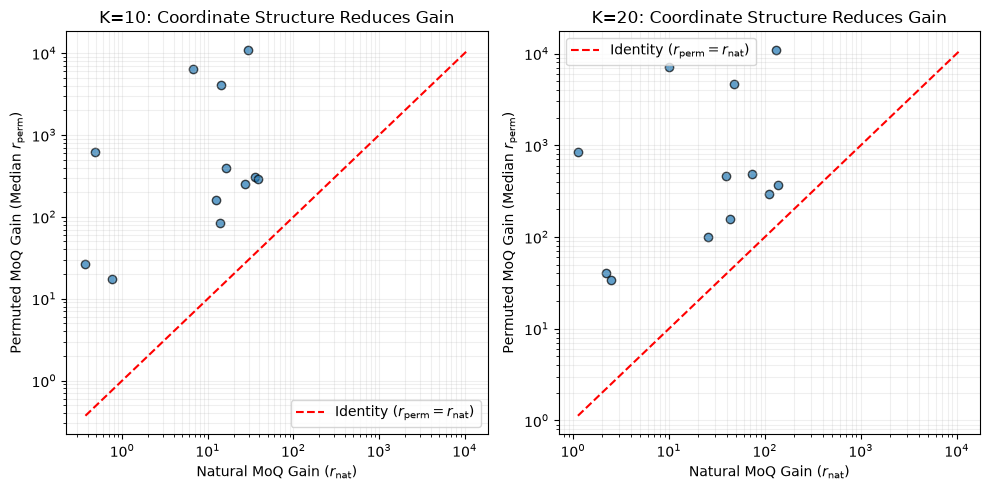

In [7]:
def plot_stage18c():
    plt.figure(figsize=(10, 5))
    
    for i, K in enumerate([10, 20]):
        plt.subplot(1, 2, i + 1)
        path = Path(f"stage18c_K{K}_soap_moq.json")
        if not path.exists():
            plt.text(0.5, 0.5, f"Missing {path.name}", ha='center')
            continue
            
        with open(path, "r") as f:
            data = json.load(f)
            
        r_nats = []
        r_perms = []
        for rec in data:
            moq_dict = rec.get("moq_corrected_permutation", {})
            if "r_nat" in moq_dict and "r_perm_median" in moq_dict:
                r_nats.append(moq_dict["r_nat"])
                r_perms.append(moq_dict["r_perm_median"])
            
        if len(r_nats) > 0:
            plt.scatter(r_nats, r_perms, alpha=0.7, edgecolors='k')
            
            max_val = max(max(r_nats), max(r_perms))
            min_val = min(min(r_nats), min(r_perms))
            plt.plot([min_val, max_val], [min_val, max_val], 'r--', label=r'Identity ($r_{\mathrm{perm}} = r_{\mathrm{nat}}$)')
            
        plt.xscale('log')
        plt.yscale('log')
        plt.xlabel(r'Natural MoQ Gain ($r_{\mathrm{nat}}$)')
        plt.ylabel(r'Permuted MoQ Gain (Median $r_{\mathrm{perm}}$)')
        plt.title(f'K={K}: Coordinate Structure Reduces Gain')
        plt.legend()
        plt.grid(True, which="both", ls="-", alpha=0.2)
        
    plt.tight_layout()
    plt.savefig("fig1_mechanism_stage18c.png", dpi=300)
    plt.show()

plot_stage18c()


### Figure 2 — Full Optimizer Transmission (Stage 20A)

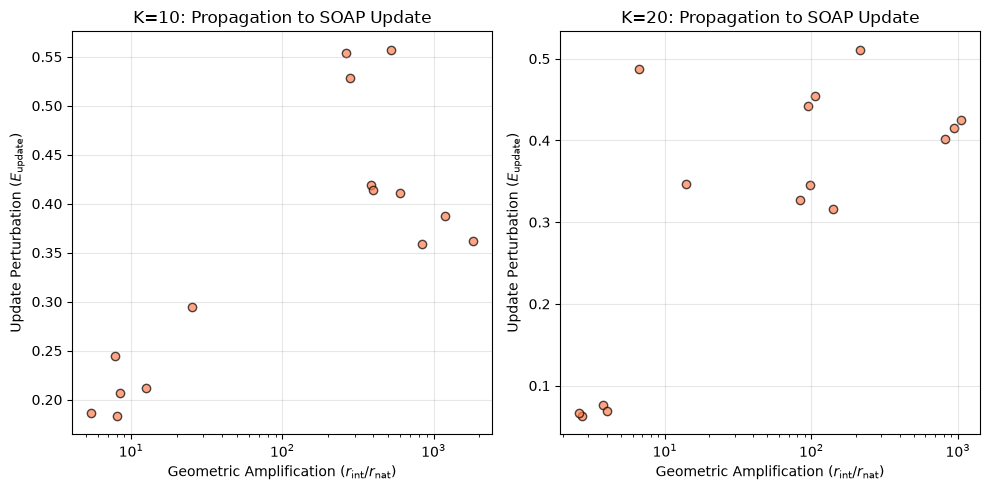

In [8]:
def plot_stage20a():
    plt.figure(figsize=(10, 5))
    
    for i, K in enumerate([10, 20]):
        plt.subplot(1, 2, i + 1)
        path = Path(f"stage20a_K{K}_soap_moq.json")
        if not path.exists():
            plt.text(0.5, 0.5, f"Missing {path.name}", ha='center')
            continue
            
        with open(path, "r") as f:
            data = json.load(f)
            
        r_ratios = []
        e_updates = []
        for rec in data:
            if "r_ratio_median" in rec and "E_update_median" in rec:
                r_ratios.append(rec["r_ratio_median"])
                e_updates.append(rec["E_update_median"])
            
        if len(r_ratios) > 0:
            plt.scatter(r_ratios, e_updates, alpha=0.7, edgecolors='k', color='coral')
            plt.xscale('log')
            
        plt.xlabel(r'Geometric Amplification ($r_{\mathrm{int}} / r_{\mathrm{nat}}$)')
        plt.ylabel(r'Update Perturbation ($E_{\mathrm{update}}$)')
        plt.title(f'K={K}: Propagation to SOAP Update')
        plt.grid(True, alpha=0.3)
        
    plt.tight_layout()
    plt.savefig("fig2_transmission_stage20a.png", dpi=300)
    plt.show()

plot_stage20a()


### Figure 3 — Coupling & Attenuation (Stage 23)

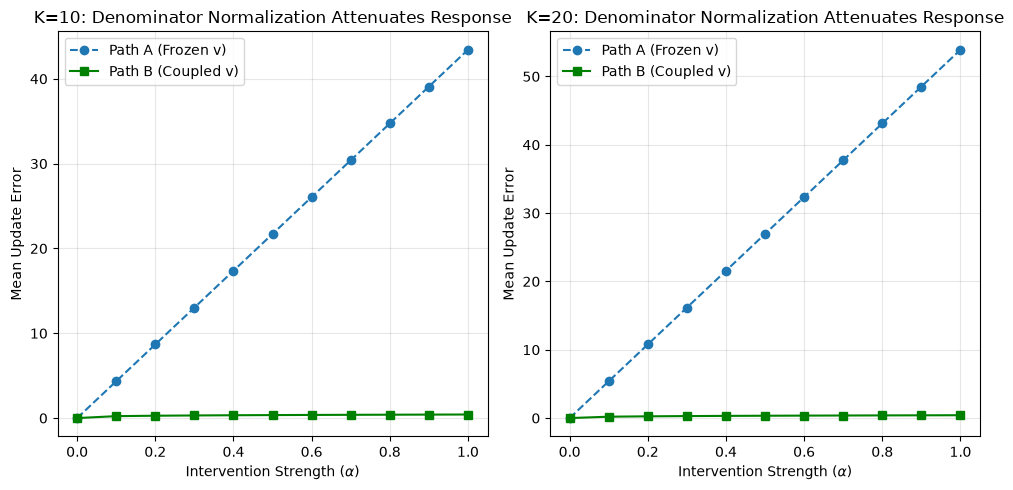

In [9]:
def plot_stage23():
    plt.figure(figsize=(10, 5))
    
    for i, K in enumerate([10, 20]):
        plt.subplot(1, 2, i + 1)
        path = Path(f"stage23_K{K}_soap_moq.json")
        if not path.exists():
            plt.text(0.5, 0.5, f"Missing {path.name}", ha='center')
            continue
            
        with open(path, "r") as f:
            data = json.load(f)
            
        # Average E_A and E_B over layers/steps for each alpha
        alpha_dict = {}
        for rec in data:
            if "alphas" in rec and "E_A_median" in rec and "E_B_median" in rec:
                alphas = rec["alphas"]
                eas = rec["E_A_median"]
                ebs = rec["E_B_median"]
                for a, ea, eb in zip(alphas, eas, ebs):
                    if a not in alpha_dict:
                        alpha_dict[a] = {"E_A": [], "E_B": []}
                    alpha_dict[a]["E_A"].append(ea)
                    alpha_dict[a]["E_B"].append(eb)
            
        if len(alpha_dict) > 0:
            alphas = sorted(list(alpha_dict.keys()))
            mean_EA = [np.mean(alpha_dict[a]["E_A"]) for a in alphas]
            mean_EB = [np.mean(alpha_dict[a]["E_B"]) for a in alphas]
            
            plt.plot(alphas, mean_EA, 'o--', label='Path A (Frozen v)')
            plt.plot(alphas, mean_EB, 's-', label='Path B (Coupled v)', color='green')
        
        plt.xlabel(r'Intervention Strength ($\alpha$)')
        plt.ylabel('Mean Update Error')
        plt.title(f'K={K}: Denominator Normalization Attenuates Response')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
    plt.tight_layout()
    plt.savefig("fig3_coupling_stage23.png", dpi=300)
    plt.show()

plot_stage23()


### Figure 4 — Final Causal Intervention & Dose-Response (Stage 26)

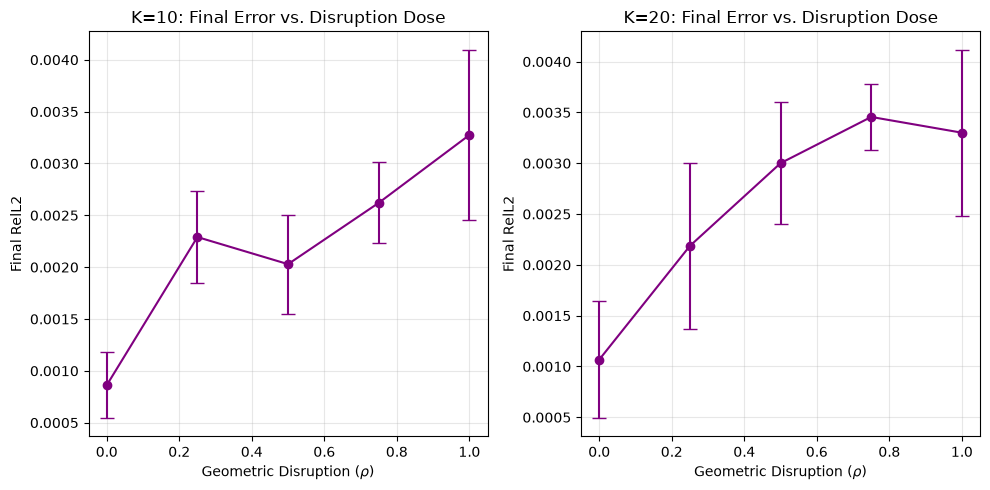

In [10]:
def plot_stage26():
    plt.figure(figsize=(10, 5))
    
    for i, K in enumerate([10, 20]):
        plt.subplot(1, 2, i + 1)
        path = Path(f"stage26_K{K}_confirmatory.json")
        if not path.exists():
            plt.text(0.5, 0.5, f"Missing {path.name}", ha='center')
            continue
            
        with open(path, "r") as f:
            data = json.load(f)
            
        rhos = sorted([float(r) for r in data.keys()])
        mean_rels = []
        std_rels = []
        
        for rho in rhos:
            rho_str = str(rho) if str(rho) in data else str(float(rho))
            for key in data.keys():
                if abs(float(key) - rho) < 1e-4:
                    rho_str = key
                    break
            
            finals = []
            for seed in data[rho_str]["summaries"]:
                finals.append(data[rho_str]["summaries"][seed]["final_rel_l2"])
                
            mean_rels.append(np.mean(finals))
            std_rels.append(np.std(finals))
            
        if len(rhos) > 0:
            plt.errorbar(rhos, mean_rels, yerr=std_rels, fmt='-o', capsize=5, color='purple')
            
        plt.xlabel(r'Geometric Disruption ($\rho$)')
        plt.ylabel('Final RelL2')
        plt.title(f'K={K}: Final Error vs. Disruption Dose')
        plt.grid(True, alpha=0.3)
        
    plt.tight_layout()
    plt.savefig("fig4_dose_response_stage26.png", dpi=300)
    plt.show()

plot_stage26()
